In [1]:
import matplotlib.pyplot as plt
import numpy as np

from bandit import Bandit

%load_ext autoreload
%autoreload 2

# 10-armed Bandit Testbed - Stationary case

## Initialize a specific 10-armed bandit

In [2]:
bandit = Bandit(10)

In [3]:
bandit._q_true

array([ 0.30471708, -1.03998411,  0.7504512 ,  0.94056472, -1.95103519,
       -1.30217951,  0.1278404 , -0.31624259, -0.01680116, -0.85304393])

In [4]:
[bandit.sample(a).item() for a in range(0, 10)];

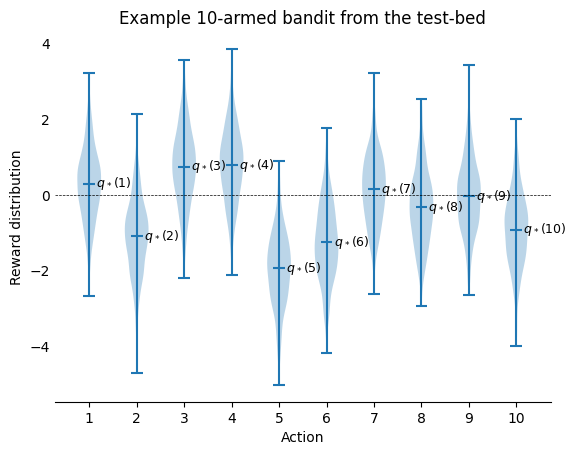

In [5]:
actions = range(0, 10)
rewards = [bandit.sample(a, 500) for a in actions]

# Create violin plot with means enabled
fig, ax = plt.subplots()
plt.title("Example 10-armed bandit from the test-bed")
parts = ax.violinplot(rewards, showmeans=True)

plt.axhline(y=0, color='k', linestyle='--', linewidth=0.5)
ax.set_xticks(range(1,11), labels=[f"{x}" for x in range(1, 11)])
plt.xlabel("Action")
plt.ylabel("Reward distribution")

# Remove top and right borders
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
plt.tick_params(axis='y', which='both', length=0)

# Extract mean segments from 'cmeans' LineCollection
mean_collection = parts["cmeans"]
paths = mean_collection.get_paths()

# Loop through paths to get coordinates and place text labels
for i, path in enumerate(paths):
  # Each path has 2 vertices for the mean horizontal line segment: start and end
  vertices = path.vertices
  mean_x = np.mean(vertices[:, 0])
  mean_y = np.mean(vertices[:, 1])

  # Add text label above or beside the mean indicator
  ax.text(
      mean_x,
      mean_y,
      f"  $q_*({i+1})$",
      verticalalignment="center",
      horizontalalignment="left",
      fontsize=9,
      color="black",
  )

plt.savefig("../images/figure_2_1.png", bbox_inches="tight")

# 10-armed Bandit Testbed - Non-Stationary case

### Set up Bandit with drifting q_true values

In [6]:
# Bandit parameters
k = 10  # number of arms in the bandit
q_true_mean = 0.0
q_true_var = 0.0
drift_var = 0.01

# Agent and test parameters
T = 10000  # number of timesteps played
epsilon = 0.1
R = 2000  # number of runs to play in the simulation

Initial optimal reward:	 0.0
Final optimal reward:	 0.98735


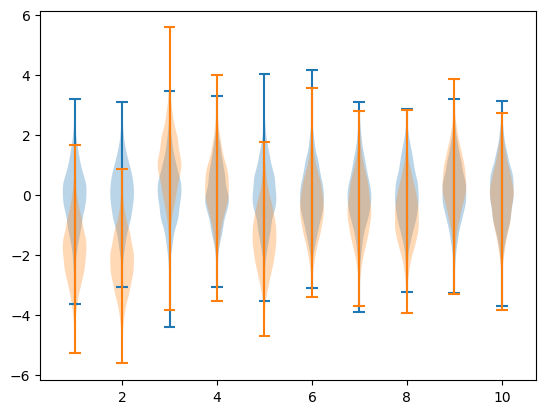

In [7]:
# Visualize an example
bandit = Bandit(k, q_true_mean=q_true_mean, q_true_var=q_true_var, drift_var=drift_var)
q_true_values = np.zeros((k, T))

rewards_start = [bandit.sample(a, R) for a in range(0, k)]
print(f"Initial optimal reward:\t {round(bandit._q_true.max().item(), 5)}")

# Take a number of time steps, at each of which the q_true valus take independent random walks
for i in range(T):
    q_true_values[:, i] = bandit._q_true
    bandit.reward(0)
rewards_end = [bandit.sample(a, R) for a in range(0, k)]
print(f"Final optimal reward:\t {round(bandit._q_true.max().item(), 5)}")

plt.violinplot(rewards_start)
plt.violinplot(rewards_end);

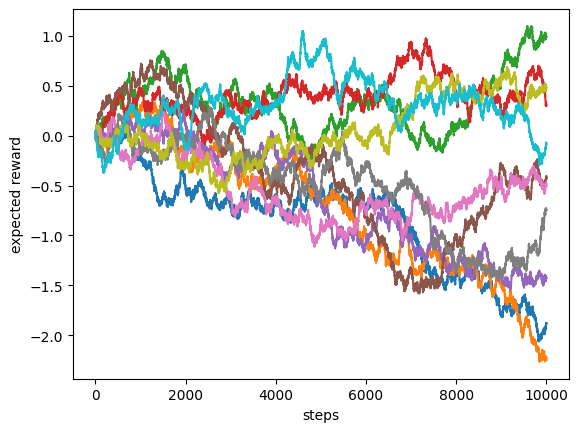

In [8]:
plt.plot(q_true_values.T);
plt.xlabel("steps")
plt.ylabel("expected reward")
plt.savefig("../images/figure_2_ns.png", bbox_inches="tight")